# Golinski speed reducer: sign-constrained Ridge surrogate for RBDO

Single notebook for **Case Study 2** of the manuscript *Sign-Constrained Surrogate Learning for Reliability-Based Design Optimization under Limited Objective Information*. Run all cells in order. On Colab the full run takes a few minutes; set `QUICK_TEST = True` in the configuration cell for a fast smoke test (5 repeats, 200,000 Monte Carlo samples).

**What it reproduces**

| Section | Content | Manuscript item |
|---|---|---|
| 3 | Conjugate virtual variables for the four ambiguous variables $x_1, x_2, x_6, x_7$ | augmented feature set |
| 4 | Five-fold CV selection of the Ridge parameter for four models, augmented and net coefficient tables, exact collapse check | coefficient tables, full-sample table |
| 5 | Learning curves over 50 repeated subsets, paired Wilcoxon tests and Hodges-Lehmann effect sizes against three comparators | earlier protocol, not used in the revised manuscript |
| 6 | Learning-curve figure | earlier protocol, not used in the revised manuscript |
| 7 | RBDO with the collapsed linear objective, FORM and COBYLA | RBDO tables |
| 8 | Monte Carlo verification of FORM, 2,000,000 samples per constraint, Wilson 95% intervals | Monte Carlo table |

**The four models.** *Unrestricted* and *sign-constrained* use the 11-feature augmented representation (each ambiguous variable $x_i$ becomes $x_i^+ = x_i$ and $x_i^- = -x_i$). *Shrinkage-matched* is the unrestricted augmented model fitted at the sign-constrained model's selected $\alpha$. *Original-space* is an unrestricted Ridge on the seven raw variables with its own selected $\alpha$.

**Conventions.** Cross-validated R2 is scored against the noisy training labels. Learning-curve R2 is scored on an independent noise-free test set of 2,000 Latin-hypercube points. The fold standard deviation is the population standard deviation over the five folds (`ddof=0`). All random number generators use fixed seeds.

> **Scope in the revised manuscript.** Sections that give the full-sample fits, the coefficient tables, the RBDO designs and the Monte Carlo verification of FORM are the source of the corresponding tables of the manuscript. The learning-curve sections of this notebook (50 repeated subsets of one 300-label pool, with the regularization strength chosen on the full pool) are the **earlier protocol**. They are kept for transparency, and **no number of the revised manuscript comes from them**. All learning-curve, noise, label-count, small-sample RBDO and statistical results of the revised manuscript come from `replicated_experiments.ipynb` (independent replicates, regularization chosen inside each training set).

In [1]:
%pip install -q openturns

Note: you may need to restart the kernel to use updated packages.


## 1. Setup and configuration

In [2]:
import os, time, warnings, itertools, zipfile
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, Bounds, LinearConstraint
from scipy.stats import qmc, norm, wilcoxon
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import openturns as ot

warnings.filterwarnings("ignore")
ot.Log.Show(ot.Log.NONE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [3]:
# ---------- statistics helpers ----------
def wilson_interval(k, n, z=1.959964):
    """Wilson score 95% interval for a binomial proportion k/n."""
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, centre - half), centre + half


def hodges_lehmann(d):
    """Hodges-Lehmann one-sample estimator: median of Walsh averages."""
    w = (d[:, None] + d[None, :]) / 2.0
    return float(np.median(w[np.triu_indices(len(d))]))


def paired_summary(a, b, n_boot=500, seed=1, tol=1e-6):
    """Paired comparison a - b.

    Returns the mean difference, the Hodges-Lehmann estimate with a bootstrap 95% CI, the number of
    repeats where a > b, and a paired Wilcoxon p-value. Differences smaller than `tol` in absolute value
    are treated as exact zeros for the Wilcoxon test: they are solver noise (about 1e-9), and ranking
    them would otherwise make the p-value depend on numerical noise rather than on the data.
    """
    d = np.asarray(a, float) - np.asarray(b, float)
    rng = np.random.default_rng(seed)
    boots = [hodges_lehmann(rng.choice(d, len(d))) for _ in range(n_boot)]
    d_test = np.where(np.abs(d) < tol, 0.0, d)
    try:
        p = float(wilcoxon(d_test).pvalue)
    except ValueError:  # every difference is (numerically) zero
        p = float("nan")
    return {"mean_diff": d.mean(), "HL": hodges_lehmann(d),
            "HL_lo": np.percentile(boots, 2.5), "HL_hi": np.percentile(boots, 97.5),
            "wins": int((d > tol).sum()), "n_nonzero": int((np.abs(d) >= tol).sum()), "p_wilcoxon": p}

In [4]:
# ---------- configuration ----------
QUICK_TEST = False            # True: 5 repeats and 200k Monte Carlo samples (smoke test only)

SEED = 42
N_BASE, N_TEST = 300, 2000
NOISE_FRAC = 0.15             # label noise: sd = 15% of the true value (heteroscedastic)
SAMPLE_SIZES = [20, 50, 100, 200, 300]
N_REPEATS = 5 if QUICK_TEST else 50
N_MC = 200_000 if QUICK_TEST else 2_000_000
ALPHA_GRID = np.logspace(-4, 4, 200)
BETA_TARGET = 3.0
COV = 0.01                    # coefficient of variation of the six random design variables

RESULTS_DIR = "results_golinski"
os.makedirs(RESULTS_DIR, exist_ok=True)
SAVED_TABLES = {}

print("QUICK_TEST:", QUICK_TEST, "| repeats:", N_REPEATS, "| MC samples:", N_MC)
print("OpenTURNS", ot.__version__)

QUICK_TEST: False | repeats: 50 | MC samples: 2000000
OpenTURNS 1.27.post1


## 2. Problem definition and data

The objective is the gear-box mass. Eleven safety margins are written so that failure is $G_i \le 0$. Eight of them ($G_1$ to $G_7$ and $G_{10}$) are probabilistic and are evaluated with FORM at $\beta_T = 3.0$. The three geometric design rules $G_8, G_9, G_{11}$ are imposed deterministically at the design values. The six variables $x_1, x_2, x_4, x_5, x_6, x_7$ are independent normal with mean equal to the design value and a coefficient of variation of 1%. The number of pinion teeth $x_3$ is an integer design choice and is treated deterministically.

In [5]:
BOUNDS = np.array([[2.6, 3.6], [0.7, 0.8], [17.0, 28.0], [7.3, 8.3], [7.3, 8.3], [2.9, 3.9], [5.0, 5.5]])
VAR_NAMES = ["x1", "x2", "x3", "x4", "x5", "x6", "x7"]
RANDOM_IDX = [0, 1, 3, 4, 5, 6]            # x3 is deterministic


def mass_true(X):
    """Analytical gear-box mass (used only to generate labels and to validate designs)."""
    X = np.atleast_2d(np.asarray(X, float))
    x1, x2, x3, x4, x5, x6, x7 = X.T
    return (0.7854 * x1 * x2**2 * (3.3333 * x3**2 + 14.9334 * x3 - 43.0934)
            - 1.508 * x1 * (x6**2 + x7**2) + 7.4777 * (x6**3 + x7**3) + 0.7854 * (x4 * x6**2 + x5 * x7**2))


def prob_margins(x1, x2, x3, x4, x5, x6, x7):
    """Probabilistic safety margins (scalars or arrays). Failure when <= 0."""
    return {
        "G1": 1 - 27 / (x1 * x2**2 * x3),
        "G2": 1 - 397.5 / (x1 * x2**2 * x3**2),
        "G3": 1 - 1.93 * x4**3 / (x2 * x3 * x6**4),
        "G4": 1 - 1.93 * x5**3 / (x2 * x3 * x7**4),
        "G5": 1100 - np.sqrt((745 * x4 / (x2 * x3)) ** 2 + 16.9e6) / (0.1 * x6**3),
        "G6": 850 - np.sqrt((745 * x5 / (x2 * x3)) ** 2 + 157.5e6) / (0.1 * x7**3),
        "G7": 40 - x2 * x3,
        "G10": x4 - 1.5 * x6 - 1.9,
    }
PROB = ["G1", "G2", "G3", "G4", "G5", "G6", "G7", "G10"]


def det_margins(x):
    """Deterministic design rules G8, G9, G11 (feasible when >= 0)."""
    return np.array([x[0] / x[1] - 5.0, 12.0 - x[0] / x[1], x[4] - 1.1 * x[6] - 1.9])


def make_training_data(seed=SEED):
    X = qmc.scale(qmc.LatinHypercube(d=7, seed=seed).random(N_BASE), BOUNDS[:, 0], BOUNDS[:, 1])
    y_true = mass_true(X)
    rng = np.random.default_rng(seed)
    return X, y_true + rng.normal(0.0, NOISE_FRAC * np.abs(y_true))


def make_test_data(seed=SEED + 1000):
    X = qmc.scale(qmc.LatinHypercube(d=7, seed=seed).random(N_TEST), BOUNDS[:, 0], BOUNDS[:, 1])
    return X, mass_true(X)


X_base, y_base = make_training_data()
X_test, y_test = make_test_data()
print("training labels:", len(y_base), "| test points:", len(y_test))
print("noisy mass range %.0f to %.0f" % (y_base.min(), y_base.max()))

training labels: 300 | test points: 2000
noisy mass range 2393 to 7056


## 3. Conjugate virtual variables

Variables whose effect on mass has competing physical pathways ($x_1, x_2, x_6, x_7$) are represented by the pair $x_i^+ = x_i$ (positive pathway) and $x_i^- = -x_i$ (negative pathway). The sign-constrained model requires every pathway coefficient to be non-negative. Because $x_i^-$ is exactly $-x_i^+$, the two columns are perfectly anti-collinear and the data identify only the net coefficient $c_i = a_i - b_i$.

In [6]:
FEATURE_NAMES = ["x1+", "x1-", "x2+", "x2-", "x3", "x4", "x5", "x6+", "x6-", "x7+", "x7-"]

def augment(X):
    X = np.atleast_2d(np.asarray(X, float))
    x1, x2, x3, x4, x5, x6, x7 = X.T
    return np.column_stack([x1, -x1, x2, -x2, x3, x4, x5, x6, -x6, x7, -x7])

F_base, F_test = augment(X_base), augment(X_test)
print("raw dimension:", X_base.shape[1], "| augmented dimension:", F_base.shape[1])

raw dimension: 7 | augmented dimension: 11


## 4. Models and full-sample fits

All models are fitted inside a pipeline that standardizes every feature before the Ridge penalty. The regularization parameter is selected by five-fold cross-validation (shuffled, seed 42) over 200 log-spaced values from $10^{-4}$ to $10^{4}$. The sign-constrained model uses scikit-learn's `positive=True` option.

In [7]:
def make_pipeline(positive, alpha=1.0):
    ridge = Ridge(alpha=alpha, positive=True, solver="lbfgs", max_iter=50000, tol=1e-12) if positive else Ridge(alpha=alpha)
    return Pipeline([("scaler", StandardScaler()), ("ridge", ridge)])

CV = KFold(5, shuffle=True, random_state=SEED)

def select_alpha(positive, features):
    gs = GridSearchCV(make_pipeline(positive), {"ridge__alpha": ALPHA_GRID}, cv=CV, scoring="r2").fit(features, y_base)
    return float(gs.best_params_["ridge__alpha"]), float(gs.best_score_)

def fold_scores(positive, alpha, features):
    s = cross_val_score(make_pipeline(positive, alpha), features, y_base, cv=CV, scoring="r2")
    return s.mean(), s.std(ddof=0)

alpha_u, _ = select_alpha(False, F_base)     # unrestricted, augmented
alpha_c, _ = select_alpha(True, F_base)      # sign-constrained, augmented
alpha_o, _ = select_alpha(False, X_base)     # original-space unrestricted

SPEC = {   # name: (positive, alpha, uses augmented features)
    "Unrestricted (augmented)":         (False, alpha_u, True),
    "Sign-constrained":                 (True,  alpha_c, True),
    "Shrinkage-matched (alpha = alpha_c)": (False, alpha_c, True),
    "Original-space unrestricted":      (False, alpha_o, False),
}
fits, rows = {}, []
for name, (pos, a, aug_flag) in SPEC.items():
    F, Ft = (F_base, F_test) if aug_flag else (X_base, X_test)
    m = make_pipeline(pos, a).fit(F, y_base)
    fits[name] = m
    mean, sd = fold_scores(pos, a, F)
    rows.append({"Model": name, "alpha": a, "CV R2 mean": mean, "CV R2 fold sd": sd,
                 "Test R2 (300 labels)": r2_score(y_test, m.predict(Ft))})
full_table = pd.DataFrame(rows)
SAVED_TABLES["sr_full_sample_performance.csv"] = full_table
display(full_table.round(4))

,Model,alpha,CV R2 mean,CV R2 fold sd,Test R2 (300 labels)
0,Unrestricted (augmented),6.6699,0.5607,0.0699,0.9753
1,Sign-constrained,7.3168,0.5631,0.0711,0.9749
2,Shrinkage-matched (alpha = alpha_c),7.3168,0.5607,0.0697,0.9749
3,Original-space unrestricted,6.6699,0.5608,0.0696,0.9752


In [8]:
def raw_coefficients(m):
    r, s = m.named_steps["ridge"], m.named_steps["scaler"]
    return r.coef_ / s.scale_

def raw_intercept(m):
    r, s = m.named_steps["ridge"], m.named_steps["scaler"]
    return float(r.intercept_ - np.sum(r.coef_ * s.mean_ / s.scale_))

cu = raw_coefficients(fits["Unrestricted (augmented)"])
cc = raw_coefficients(fits["Sign-constrained"])
coef = pd.DataFrame({"Feature": FEATURE_NAMES, "Unrestricted": cu, "Sign-constrained": cc})
coef["Binding?"] = np.where((np.abs(cc) < 1e-8) & (cu < -1e-8), "Yes (structural)", "No")
SAVED_TABLES["sr_augmented_coefficients.csv"] = coef
print("Augmented coefficients (the 'Binding' entries are a structural consequence of the anti-collinear pairs):")
display(coef.round(3))

def collapse(m):
    """Collapse each conjugate pair to its net coefficient c_i = a_i - b_i; return the 7-variable linear model."""
    w = raw_coefficients(m)
    net = np.array([w[0] - w[1], w[2] - w[3], w[4], w[5], w[6], w[7] - w[8], w[9] - w[10]])
    return net, raw_intercept(m)

net_u, b_u = collapse(fits["Unrestricted (augmented)"])
net_c, b_c = collapse(fits["Sign-constrained"])
# The unrestricted reference of the manuscript is the original-space Ridge (no virtual variables, no sign constraints).
net_o, b_o = raw_coefficients(fits["Original-space unrestricted"]), raw_intercept(fits["Original-space unrestricted"])
net_table = pd.DataFrame({"Variable": VAR_NAMES, "Unrestricted (net, original space)": net_o, "Sign-constrained (net)": net_c,
                          "Ambiguous?": ["Yes", "Yes", "No", "No", "No", "Yes", "Yes"]})
net_table["Relative difference (%)"] = 100 * (net_table["Sign-constrained (net)"] - net_table["Unrestricted (net, original space)"]) / net_table["Unrestricted (net, original space)"]
SAVED_TABLES["sr_net_coefficients.csv"] = net_table
display(net_table.round(3))

# exact collapse check on 100 fresh Latin-hypercube points
X_chk = qmc.scale(qmc.LatinHypercube(d=7, seed=SEED + 77).random(100), BOUNDS[:, 0], BOUNDS[:, 1])
for name, net, b in [("Unrestricted (augmented)", net_u, b_u), ("Sign-constrained", net_c, b_c)]:
    err = np.max(np.abs(fits[name].predict(augment(X_chk)) - (X_chk @ net + b)))
    print("%-26s max |augmented - collapsed| = %.2e" % (name, err))
    assert err < 1e-8

Augmented coefficients (the 'Binding' entries are a structural consequence of the anti-collinear pairs):


,Feature,Unrestricted,Sign-constrained,Binding?
0,x1+,394.996,779.511,No
1,x1-,-394.996,0.000,Yes (structural)
2,x2+,3890.771,7674.763,No
3,x2-,-3890.771,0.000,Yes (structural)
4,x3,204.138,203.683,No
5,x4,31.728,30.169,No
6,x5,28.088,26.963,No
7,x6+,141.525,280.346,No
8,x6-,-141.525,0.000,Yes (structural)
9,x7+,283.150,558.278,No


,Variable,"Unrestricted (net, original space)",Sign-constrained (net),Ambiguous?,Relative difference (%)
0,x1,780.821,779.511,Yes,-0.168
1,x2,7696.550,7674.763,Yes,-0.283
2,x3,204.135,203.683,No,-0.221
3,x4,30.519,30.169,No,-1.147
4,x5,27.351,26.963,No,-1.420
5,x6,280.266,280.346,Yes,0.029
6,x7,560.289,558.278,Yes,-0.359


Unrestricted (augmented)   max |augmented - collapsed| = 4.55e-12
Sign-constrained           max |augmented - collapsed| = 5.46e-12


## 5. Learning curves (50 repeated subsets) (earlier protocol, not used in the manuscript)

Each reduced size uses 50 random subsets drawn without replacement from the 300-label pool. All four models are fitted on the same subset within a repeat, so every comparison is paired. Each model keeps the regularization strength selected on the full 300-label set. The 300-label case is a single fit on the whole pool. The test set is noise-free and independent.

In [9]:
rng = np.random.default_rng(SEED + 300)
records, t0 = [], time.time()
for n in SAMPLE_SIZES:
    for rep in range(1 if n == N_BASE else N_REPEATS):
        idx = np.arange(N_BASE) if n == N_BASE else rng.choice(N_BASE, size=n, replace=False)
        for name, (pos, a, aug_flag) in SPEC.items():
            Ftr, Fte = (augment(X_base[idx]), F_test) if aug_flag else (X_base[idx], X_test)
            m = make_pipeline(pos, a).fit(Ftr, y_base[idx])
            records.append({"n": n, "rep": rep, "model": name, "R2": r2_score(y_test, m.predict(Fte))})
lc = pd.DataFrame(records)
print("learning curves done in %.0f s" % (time.time() - t0))

order = ["Unrestricted (augmented)", "Sign-constrained", "Shrinkage-matched (alpha = alpha_c)", "Original-space unrestricted"]
mean_lc = lc.pivot_table(index="n", columns="model", values="R2")[order]
SAVED_TABLES["sr_learning_curve_table.csv"] = mean_lc.reset_index()
display(mean_lc.round(4))

rows = []
for comp in [order[0], order[2], order[3]]:
    for n in SAMPLE_SIZES[:-1]:
        a = lc[(lc.n == n) & (lc.model == "Sign-constrained")].sort_values("rep").R2.values
        b = lc[(lc.n == n) & (lc.model == comp)].sort_values("rep").R2.values
        s = paired_summary(a, b); s.update({"comparator": comp, "n": n}); rows.append(s)
tests = pd.DataFrame(rows)[["comparator", "n", "mean_diff", "HL", "HL_lo", "HL_hi", "wins", "p_wilcoxon"]]
SAVED_TABLES["sr_paired_tests.csv"] = tests
print("Sign-constrained minus comparator: Hodges-Lehmann median difference in test R2, 95% bootstrap CI, paired Wilcoxon p")
display(tests.style.format({"mean_diff": "{:.4f}", "HL": "{:.4f}", "HL_lo": "{:.4f}", "HL_hi": "{:.4f}", "p_wilcoxon": "{:.2e}"}))

learning curves done in 2 s


model,Unrestricted (augmented),Sign-constrained,Shrinkage-matched (alpha = alpha_c),Original-space unrestricted
n,,,,
20,0.6223,0.6905,0.6170,0.6611
50,0.8691,0.8822,0.8662,0.8721
100,0.9388,0.9407,0.9377,0.9391
200,0.9661,0.9663,0.9656,0.9660
300,0.9753,0.9749,0.9749,0.9752


Sign-constrained minus comparator: Hodges-Lehmann median difference in test R2, 95% bootstrap CI, paired Wilcoxon p


,comparator,n,mean_diff,HL,HL_lo,HL_hi,wins,p_wilcoxon
0,Unrestricted (augmented),20,0.0682,0.0579,0.0437,0.0791,47,3.68e-13
1,Unrestricted (augmented),50,0.0131,0.0078,0.0039,0.0146,39,6.01e-06
2,Unrestricted (augmented),100,0.0019,0.0016,0.0004,0.0028,29,8.33e-03
3,Unrestricted (augmented),200,0.0002,0.0000,-0.0003,0.0004,26,8.63e-01
4,Shrinkage-matched (alpha = alpha_c),20,0.0735,0.0637,0.0496,0.0864,49,8.88e-15
5,Shrinkage-matched (alpha = alpha_c),50,0.0160,0.0106,0.0070,0.0165,43,5.32e-10
6,Shrinkage-matched (alpha = alpha_c),100,0.0030,0.0026,0.0015,0.0038,34,2.56e-05
7,Shrinkage-matched (alpha = alpha_c),200,0.0007,0.0005,0.0003,0.0009,33,2.41e-04
8,Original-space unrestricted,20,0.0295,0.0182,0.0069,0.0361,32,1.94e-04
9,Original-space unrestricted,50,0.0101,0.0034,0.0006,0.0113,27,1.45e-02


## 6. Learning-curve figure (earlier protocol, not used in the manuscript)

Line styles and markers differ between models so the figure is readable in grayscale and for readers with color-vision deficiency.

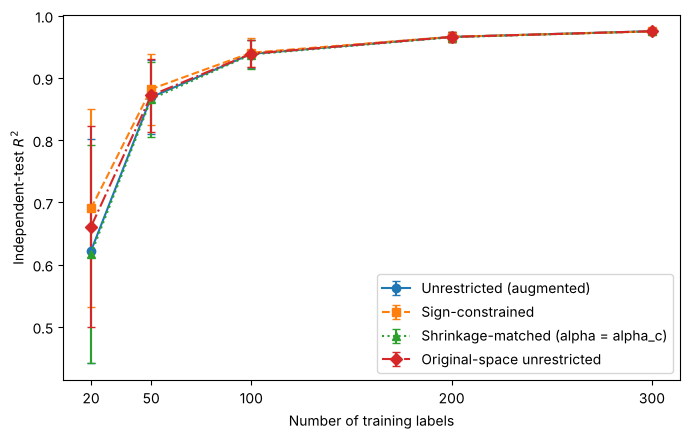

In [10]:
styles = {order[0]: ("o", "-"), order[1]: ("s", "--"), order[2]: ("^", ":"), order[3]: ("D", "-.")}
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, (mk, ls) in styles.items():
    d = lc[lc.model == name].groupby("n").R2.agg(["mean", "std"]).reset_index()
    ax.errorbar(d.n, d["mean"], yerr=d["std"].fillna(0), marker=mk, linestyle=ls, capsize=3, label=name)
ax.set_xlabel("Number of training labels"); ax.set_ylabel("Independent-test $R^2$")
ax.set_xticks(SAMPLE_SIZES); ax.legend(); fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "FigureLC_SR_v3.png"), dpi=300, bbox_inches="tight")
plt.show()

## 7. RBDO with FORM and COBYLA

The learned surrogate is used only for the objective, expressed through the collapsed seven-variable linear model. FORM (Abdo-Rackwitz in OpenTURNS) evaluates the eight probabilistic constraints on the original limit states with $\beta_i \ge 3.0$; the three design rules are imposed on the design values. Design variables are normalized to $[0,1]^7$ and the objective is divided by 3000 so that COBYLA's trust region works on an O(1) scale. The search starts from the design-box corner that satisfies all design rules and has the largest minimum FORM reliability index. If a FORM run fails to converge it returns $\beta = -10$, so the point is treated as infeasible.

In [11]:
def _g_fun(k, x_fixed):
    def f(u):
        v = np.array(x_fixed, float); v[RANDOM_IDX] = u
        return [float(prob_margins(*v)[PROB[k]])]
    return ot.PythonFunction(6, 1, f)


@lru_cache(maxsize=None)
def _form_cached(k, x_rounded):
    x = np.array(x_rounded)
    dist = ot.JointDistribution([ot.Normal(float(x[i]), COV * abs(float(x[i]))) for i in RANDOM_IDX])
    event = ot.ThresholdEvent(ot.CompositeRandomVector(_g_fun(k, x), ot.RandomVector(dist)), ot.LessOrEqual(), 0.0)
    try:
        algo = ot.FORM(ot.AbdoRackwitz(), event, ot.Point([float(x[i]) for i in RANDOM_IDX])); algo.run()
        r = algo.getResult()
        return float(r.getEventProbability()), float(r.getGeneralisedReliabilityIndex())
    except RuntimeError:
        return 1.0, -10.0


def form(x):
    key = tuple(np.round(np.asarray(x, float), 8))
    return {PROB[k]: _form_cached(k, key) for k in range(len(PROB))}

to_x = lambda z: BOUNDS[:, 0] + np.asarray(z) * (BOUNDS[:, 1] - BOUNDS[:, 0])
to_z = lambda x: (np.asarray(x) - BOUNDS[:, 0]) / (BOUNDS[:, 1] - BOUNDS[:, 0])

def is_feasible(x, tol=1e-5):
    f = form(x)
    return all(v[1] >= BETA_TARGET - tol for v in f.values()) and bool((det_margins(x) >= -tol).all())


def solve_rbdo(objective, x0, rhobeg=0.10, tol=1e-7, maxiter=5000):
    cons = [{"type": "ineq", "fun": (lambda z, j=j: z[j])} for j in range(7)]
    cons += [{"type": "ineq", "fun": (lambda z, j=j: 1.0 - z[j])} for j in range(7)]
    cons += [{"type": "ineq", "fun": (lambda z, k=k: form(to_x(z))[k][1] - BETA_TARGET)} for k in PROB]
    cons += [{"type": "ineq", "fun": (lambda z, j=j: det_margins(to_x(z))[j])} for j in range(3)]
    r = minimize(lambda z: objective(to_x(z)) / 3000.0, to_z(x0), method="COBYLA", constraints=cons,
                 options={"maxiter": maxiter, "rhobeg": rhobeg, "tol": tol, "catol": 1e-6})
    x = to_x(r.x)
    return x, is_feasible(x), r


# starting point: the best design-box corner
t0 = time.time()
scored = []
for corner in itertools.product(*[(BOUNDS[i, 0], BOUNDS[i, 1]) for i in range(7)]):
    c = np.array(corner)
    if (det_margins(c) < -1e-8).any():
        continue
    scored.append((min(v[1] for v in form(c).values()), c))
scored.sort(key=lambda t: -t[0])
start_beta, start = scored[0]
print("corners satisfying the design rules: %d | best minimum beta %.3f" % (len(scored), start_beta))
print("starting design:", np.round(start, 3), "(%.0f s)" % (time.time() - t0))
assert start_beta >= BETA_TARGET

corners satisfying the design rules: 16 | best minimum beta 3.893
starting design: [ 3.6  0.7 28.   8.3  8.3  3.9  5.5] (2 s)


In [12]:
objectives = {
    "Full information": lambda x: float(mass_true(np.asarray(x).reshape(1, -1))[0]),
    "Unrestricted Ridge": lambda x: float(np.asarray(x) @ net_o + b_o),
    "Sign-constrained Ridge": lambda x: float(np.asarray(x) @ net_c + b_c),
}
rbdo_rows, designs = [], {}
for name, obj in objectives.items():
    x, ok, res = solve_rbdo(obj, start)
    f, dm = form(x), det_margins(x)
    designs[name] = x
    rbdo_rows.append({"Method": name, **{VAR_NAMES[i]: x[i] for i in range(7)},
                      "Surrogate mass": obj(x), "True mass": float(mass_true(x.reshape(1, -1))[0]),
                      **{"beta_" + k: f[k][1] for k in PROB},
                      "margin_G8": dm[0], "margin_G9": dm[1], "margin_G11": dm[2], "feasible": ok})
    print("%-24s feasible=%s  (%.0f s)" % (name, ok, time.time() - t0))
rbdo = pd.DataFrame(rbdo_rows)
SAVED_TABLES["sr_rbdo_results.csv"] = rbdo
display(rbdo[["Method"] + VAR_NAMES + ["Surrogate mass", "True mass", "feasible"]].round(4))
display(rbdo[["Method"] + ["beta_" + k for k in PROB] + ["margin_G8", "margin_G9", "margin_G11"]].round(3))
assert rbdo["feasible"].all(), "an RBDO result is infeasible: do not use it"

Full information         feasible=True  (9 s)


Unrestricted Ridge       feasible=True  (13 s)


Sign-constrained Ridge   feasible=True  (18 s)


,Method,x1,x2,x3,x4,x5,x6,x7,Surrogate mass,True mass,feasible
0,Full information,3.5,0.7,17.0,7.3507,7.8952,3.4539,5.4502,3133.5267,3133.5267,True
1,Unrestricted Ridge,3.5,0.7,17.0,7.3507,7.8952,3.4539,5.4502,3091.0580,3133.5275,True
2,Sign-constrained Ridge,3.5,0.7,17.0,7.3507,7.8952,3.4539,5.4502,3093.8312,3133.5276,True


,Method,beta_G1,beta_G2,beta_G3,beta_G4,beta_G5,beta_G6,beta_G7,beta_G10,margin_G8,margin_G9,margin_G11
0,Full information,3.387,9.483,15.085,37.519,3.0,3.0,37.519,3.0,0.0,7.0,-0.0
1,Unrestricted Ridge,3.387,9.483,15.086,37.519,3.0,3.0,37.519,3.0,-0.0,7.0,0.0
2,Sign-constrained Ridge,3.387,9.483,15.086,37.519,3.0,3.0,37.519,3.0,0.0,7.0,0.0


In [13]:
# Regression check against the values printed in the manuscript (differences reflect rounding to four decimals)
paper_design = np.array([3.5, 0.7, 17.0, 7.3507, 7.8952, 3.4539, 5.4502])
paper_masses = {"Full information": (3133.528, 3133.528), "Unrestricted Ridge": (3091.058, 3133.528),
                "Sign-constrained Ridge": (3093.831, 3133.528)}
for name, x in designs.items():
    sm, tm = paper_masses[name]
    print("%-24s max |design - manuscript| = %.1e | surrogate mass %.3f (manuscript %.3f) | true mass %.3f (manuscript %.3f)" % (
        name, np.max(np.abs(x - paper_design)), objectives[name](x), sm, mass_true(x.reshape(1, -1))[0], tm))

Full information         max |design - manuscript| = 4.5e-05 | surrogate mass 3133.527 (manuscript 3133.528) | true mass 3133.527 (manuscript 3133.528)
Unrestricted Ridge       max |design - manuscript| = 4.5e-05 | surrogate mass 3091.058 (manuscript 3091.058) | true mass 3133.528 (manuscript 3133.528)
Sign-constrained Ridge   max |design - manuscript| = 4.5e-05 | surrogate mass 3093.831 (manuscript 3093.831) | true mass 3133.528 (manuscript 3133.528)


## 8. Monte Carlo verification of FORM

The six random variables are sampled directly and the original limit states are evaluated on every sample at each final design. The three Ridge designs coincide here (five constraints are simultaneously active), so the table is shown for each design, using the same random draws for all three. Constraints with $\beta \gtrsim 5$ have failure probabilities that this sample size cannot resolve, so zero observed failures is consistent with, but not a tight confirmation of, the FORM value.

In [14]:
# One set of standard-normal draws is shared by all designs (common random numbers),
# so differences between designs are not Monte Carlo noise.
rng_mc = np.random.default_rng(SEED + 2026)
Z = rng_mc.standard_normal((N_MC, len(RANDOM_IDX)))
mc_rows = []
for name, x in designs.items():
    V = np.tile(x, (N_MC, 1))
    for j, i in enumerate(RANDOM_IDX):
        V[:, i] = x[i] + COV * abs(x[i]) * Z[:, j]
    g = prob_margins(*V.T)
    f = form(x)
    for k in PROB:
        fails = int((g[k] <= 0).sum()); lo, hi = wilson_interval(fails, N_MC)
        mc_rows.append({"Design": name, "Constraint": k, "beta_FORM": f[k][1], "pf_FORM": f[k][0],
                        "pf_MC": fails / N_MC, "CI_low": lo, "CI_high": hi, "Failures": fails,
                        "FORM inside CI": lo <= f[k][0] <= hi})
mc = pd.DataFrame(mc_rows)
SAVED_TABLES["sr_monte_carlo_verification.csv"] = mc
with pd.option_context("display.float_format", "{:.3e}".format):
    display(mc[mc.Design == "Sign-constrained Ridge"])
print("All resolvable constraints agree with FORM:", bool(mc.loc[mc.Failures > 100, "FORM inside CI"].all()))

,Design,Constraint,beta_FORM,pf_FORM,pf_MC,CI_low,CI_high,Failures,FORM inside CI
16,Sign-constrained Ridge,G1,3.387e+00,3.533e-04,3.595e-04,3.342e-04,3.867e-04,719,True
17,Sign-constrained Ridge,G2,9.483e+00,1.232e-21,0.000e+00,0.000e+00,1.921e-06,0,True
18,Sign-constrained Ridge,G3,1.509e+01,1.009e-51,0.000e+00,0.000e+00,1.921e-06,0,True
19,Sign-constrained Ridge,G4,3.752e+01,0.000e+00,0.000e+00,0.000e+00,1.921e-06,0,True
20,Sign-constrained Ridge,G5,3.000e+00,1.350e-03,1.311e-03,1.261e-03,1.362e-03,2621,True
21,Sign-constrained Ridge,G6,3.000e+00,1.350e-03,1.309e-03,1.260e-03,1.361e-03,2619,True
22,Sign-constrained Ridge,G7,3.752e+01,0.000e+00,0.000e+00,0.000e+00,1.921e-06,0,True
23,Sign-constrained Ridge,G10,3.000e+00,1.350e-03,1.375e-03,1.325e-03,1.428e-03,2751,True


All resolvable constraints agree with FORM: True


## 9. Save results

In [15]:
# ---------- save everything and offer a download in Colab ----------
def save_table(df, name, index=False):
    path = os.path.join(RESULTS_DIR, name)
    df.to_csv(path, index=index)
    return path

for _name, _df in SAVED_TABLES.items():
    save_table(_df, _name)
zip_path = RESULTS_DIR.rstrip("/") + ".zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for _f in sorted(os.listdir(RESULTS_DIR)):
        zf.write(os.path.join(RESULTS_DIR, _f), _f)
print("Saved", len(os.listdir(RESULTS_DIR)), "files to", RESULTS_DIR, "and", zip_path)
try:
    from google.colab import files  # only available inside Colab
    files.download(zip_path)
except Exception:
    pass

Saved 8 files to results_golinski and results_golinski.zip


**Reproducibility notes.** Seeds: training design `SEED`, test design `SEED + 1000`, subset resampling `SEED + 300`, collapse check `SEED + 77`, Monte Carlo `SEED + 2026`. Library versions can change the last digits of solver-based quantities but not the structure of the results.